In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [22]:
df=pd.read_csv("/content/PhiUSIIL_Phishing_URL_Dataset - PhiUSIIL_Phishing_URL_Dataset (1).csv")
print(df.head())
print("Dataset Shape:", df.shape)
print(df.columns.tolist())

     FILENAME                                 URL  URLLength  \
0  521848.txt    https://www.southbankmosaics.com         31   
1   31372.txt            https://www.uni-mainz.de         23   
2  597387.txt      https://www.voicefmradio.co.uk         29   
3  554095.txt         https://www.sfnmjournal.com         26   
4  151578.txt  https://www.rewildingargentina.org         33   

                       Domain  DomainLength  IsDomainIP  TLD  \
0    www.southbankmosaics.com            24           0  com   
1            www.uni-mainz.de            16           0   de   
2      www.voicefmradio.co.uk            22           0   uk   
3         www.sfnmjournal.com            19           0  com   
4  www.rewildingargentina.org            26           0  org   

   URLSimilarityIndex  CharContinuationRate  TLDLegitimateProb  ...  Pay  \
0               100.0              1.000000           0.522907  ...  0.0   
1               100.0              0.666667           0.032650  ...  0.0   
2 

In [23]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import(
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,

)

In [24]:
df=pd.read_csv("/content/PhiUSIIL_Phishing_URL_Dataset - PhiUSIIL_Phishing_URL_Dataset (1).csv")
print("Dataset shape:",df.shape)
print("Missing Values:",df.isnull().sum().sum())
print("\nOriginal Class Distribution:")
print(df["label"].value_counts())

df=df.dropna(subset=["label"]).copy()

y=(df["label"]==0).astype(int)

X=df.drop(
    columns=["label","URL", "Domain", "TLD", "Title"],
    errors="ignore"
)

X=X.select_dtypes(include=np.number).copy()

X=X.replace ([np.inf, -np.inf], np.nan)
X=X.fillna(X.median())

print("\nFeatures:", X.shape)
print("Target distribution:")
print(y.value_counts())

Dataset shape: (234834, 56)
Missing Values: 36

Original Class Distribution:
label
1.0    134293
0.0    100540
Name: count, dtype: int64

Features: (234833, 50)
Target distribution:
label
0    134293
1    100540
Name: count, dtype: int64


In [25]:
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 187866
Testing samples: 46967


In [26]:
model=make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
)
model.fit(X_train, y_train)
print("\nSVM model trained successfully!")


SVM model trained successfully!


In [27]:
y_pred=model.predict(X_test)
y_score=model.decision_function(X_test)

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted labels:")
print(y_pred[:10])


First 10 actual labels:
[0 0 0 1 1 0 0 1 0 0]

First 10 predicted labels:
[0 0 0 1 1 0 0 1 0 0]



Confusion Matrix:
[[26859     0]
 [    0 20108]]


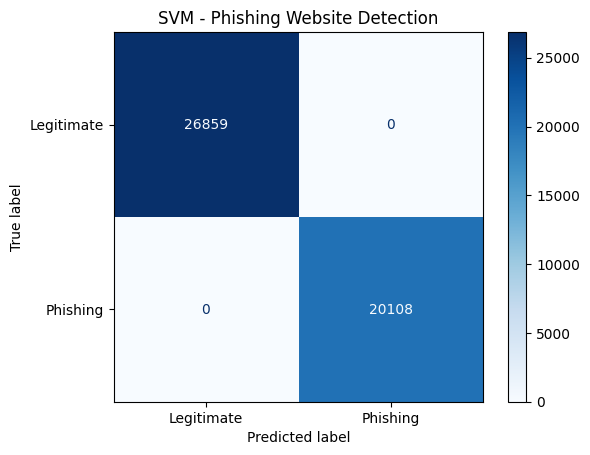

In [28]:
cm=confusion_matrix(y_test, y_pred, labels=[0,1])
print("\nConfusion Matrix:")
print(cm)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate","Phishing"]
).plot(cmap="Blues", values_format="d")
plt.title("SVM - Phishing Website Detection")
plt.show()

In [29]:
precision=precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall=recall_score(
    y_test, y_pred, zero_division=0
)

f1=f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc=roc_auc_score(
    y_test, y_score
)

print("\n=========Model Performance=========")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")



=========Model Performance=========
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
ROC AUC: 1.0000


In [30]:

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0,1],
        target_names=["Legitimate","Phishing"],
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     26859
    Phishing       1.00      1.00      1.00     20108

    accuracy                           1.00     46967
   macro avg       1.00      1.00      1.00     46967
weighted avg       1.00      1.00      1.00     46967



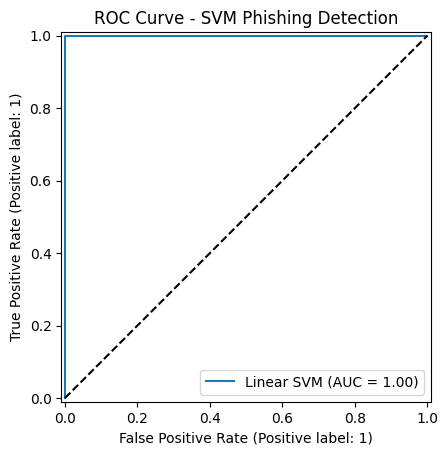

In [31]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_score,
    name="Linear SVM"
)
plt.plot([0,1],[0,1], "k--")
plt.title("ROC Curve - SVM Phishing Detection")
plt.show()